# Классворк лекции 17. Визуализация и проверка гипотез

Вы аналитик музыкального стримингового сервиса. Продакт-менеджер выдвинул несколько гипотез про каталог.
Проверь их данными и графиками.

Данные сырые: `tracks_v2.csv` (треки) и `artists_v2.csv` (артисты). **Сначала почистим, потом анализируем.**

Поля `tracks_v2.csv`: track_id, title, artist_id, genre, year, duration_ms, energy, danceability,
streams, in_playlist, explicit, marketing_spend. Поля `artists_v2.csv`: artist_id, name, country, followers.

In [21]:
%matplotlib inline
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

tracks = pd.read_csv("tracks_v2.csv")
artists = pd.read_csv("artists_v2.csv")
print(tracks.shape, artists.shape)

(3030, 12) (80, 4)


## 1. Разведка и очистка

Сколько в каталоге **реальных** треков и сколько жанров? Данные грязные: дубликаты, разное написание жанров,
`streams` хранятся текстом. Сначала приведи в порядок.

In [22]:
print(tracks)

     track_id       title artist_id       genre  year  duration_ms  energy  \
0       T2492  Track 2492      A039        rock  2022       197000   0.792   
1       T1008  Track 1008      A044         pop  2012       245000   0.552   
2       T2350  Track 2350      A040         POP  2011       239000   0.697   
3       T2284  Track 2284      A020         Поп  2016       224000   0.934   
4       T1091  Track 1091      A069     hip-hop  2017       214000   0.535   
...       ...         ...       ...         ...   ...          ...     ...   
3025    T1697  Track 1697      A066      HipHop  2024       182000   0.307   
3026    T0332   Track 332      A020        Rock  2022       216000   0.861   
3027    T1293  Track 1293      A053        Jazz  2016       224000   0.644   
3028    T1104  Track 1104      A070  electronic  2013       247000   0.120   
3029    T1945  Track 1945      A028         Поп  2019       239000   0.552   

      danceability      streams  in_playlist  explicit  marketi

In [23]:
# Дубликаты
print("Дубликатов строк:", tracks.duplicated().sum())
print("Дубликатов track_id:", tracks.duplicated(subset='track_id').sum())

tracks = tracks.drop_duplicates()
tracks = tracks.drop_duplicates(subset='track_id')

# Жанры
tracks['genre'] = tracks['genre'].str.lower().str.strip()

tracks['genre'] = tracks['genre'].replace({
    'поп': 'pop',
    'hiphop': 'hip-hop'
})

# Streams -> число
tracks['streams'] = (
    tracks['streams']
    .astype(str)
    .str.replace(' ', '', regex=False)
)

tracks['streams'] = pd.to_numeric(tracks['streams'], errors='coerce')

# Проверка
print("Уникальных треков:", tracks['track_id'].nunique())
print("Уникальных жанров:", tracks['genre'].nunique())
print(tracks['genre'].value_counts())

Дубликатов строк: 30
Дубликатов track_id: 30
Уникальных треков: 3000
Уникальных жанров: 5
genre
pop           892
hip-hop       671
rock          560
electronic    512
jazz          365
Name: count, dtype: int64


In [24]:
tracks

,track_id,title,artist_id,genre,year,duration_ms,energy,danceability,streams,in_playlist,explicit,marketing_spend
0,T2492,Track 2492,A039,rock,2022,197000,0.792,0.641,633716.0,0,False,12292
1,T1008,Track 1008,A044,pop,2012,245000,0.552,0.536,7904116.0,0,False,34885
2,T2350,Track 2350,A040,pop,2011,239000,0.697,0.739,NaN,1,True,26397
3,T2284,Track 2284,A020,pop,2016,224000,0.934,0.491,122413220.0,1,True,4943
4,T1091,Track 1091,A069,hip-hop,2017,214000,0.535,0.178,1898223.0,0,True,18814
...,...,...,...,...,...,...,...,...,...,...,...,...
3025,T1697,Track 1697,A066,hip-hop,2024,182000,0.307,0.581,243045.0,0,True,47268
3026,T0332,Track 332,A020,rock,2022,216000,0.861,0.586,628095.0,0,False,27217
3027,T1293,Track 1293,A053,jazz,2016,224000,0.644,0.751,722836.0,0,False,43102
3028,T1104,Track 1104,A070,electronic,2013,247000,0.120,0.697,76511619.0,1,True,27028


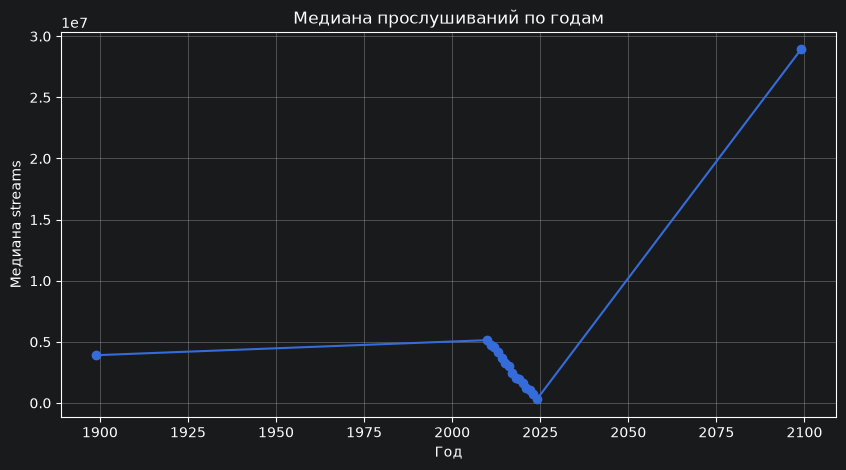

In [25]:
streams_by_year = (
    tracks.groupby('year')['streams']
    .median()
    .sort_index()
)

plt.figure(figsize=(10, 5))
plt.plot(streams_by_year.index, streams_by_year.values, marker='o')
plt.title('Медиана прослушиваний по годам')
plt.xlabel('Год')
plt.ylabel('Медиана streams')
plt.grid(True)
plt.show()

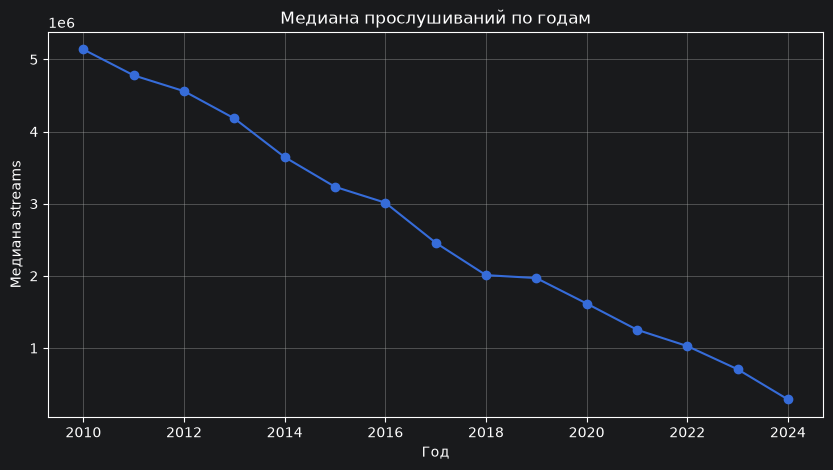

In [26]:
tracks = tracks[(tracks['year'] >= 2000) & (tracks['year'] <= 2026)]

streams_by_year = (
    tracks.groupby('year')['streams']
    .median()
    .sort_index()
)

plt.figure(figsize=(10, 5))
plt.plot(streams_by_year.index, streams_by_year.values, marker='o')
plt.title('Медиана прослушиваний по годам')
plt.xlabel('Год')
plt.ylabel('Медиана streams')
plt.grid(True)
plt.show()

## 2. Распределение прослушиваний

Построй   `streams` и опиши форму. Что показательнее для такой формы, среднее или медиана?

## 3. Гипотеза продакт-менеджера

ПМ уверен: чем энергичнее и танцевальнее трек, тем больше прослушиваний.
Проверь scatter `energy` vs `streams` и `danceability` vs `streams` + корреляцию.
Если связи нет, найди, что **реально** двигает прослушивания (посмотри на остальные столбцы).

## 4. Тренд: треки стали короче?

Построй среднюю длительность трека по годам. Будь внимателен к **единицам** длительности и к **годам**.

## 5. Жанры

Какой жанр приносит больше всего прослушиваний? Столбчатая диаграмма медианы `streams` по жанрам.

## 6. Explicit-треки

Получают ли explicit-треки больше прослушиваний? Посчитай медиану **в целом**, а потом **внутри каждого жанра**.
Сходятся ли выводы? Если нет, объясни почему.

## 7. Старые треки популярнее?

Построй медиану `streams` по годам. Потом подумай: честно ли сравнивать треки разного возраста по **суммарным**
прослушиваниям? Попробуй `streams`, делённые на возраст трека `(2025 - year)`.

## 8. Маркетинг и прослушивания

Связан ли маркетинговый бюджет `marketing_spend` с прослушиваниями? Построй scatter и посчитай корреляцию.
Потом убери 1% самых популярных треков и пересчитай корреляцию. Что произошло и почему?

## 9 (опционально). Узбекские артисты vs зарубежные

Правда ли, что узбекские артисты набирают меньше? Соедини `tracks` с `artists`, нормализуй страну, сравни.
Потом проверь: не в плейлистах ли дело?

## Выводы

По каждой гипотезе запиши: подтвердилась она или нет и почему. И перечисли **ловушки**, которые ты нашёл в данных.